## Import Libraries

In [1]:
import requests
import pandas as pd
from bs4 import BeautifulSoup

print("All libraries imported successfully")

All libraries imported successfully


In [2]:
import requests

url = "https://quotes.toscrape.com/"

response = requests.get(url, timeout=15)

print("Status code:", response.status_code)
print(response.text[:1000])


Status code: 200
<!DOCTYPE html>
<html lang="en">
<head>
	<meta charset="UTF-8">
	<title>Quotes to Scrape</title>
    <link rel="stylesheet" href="/static/bootstrap.min.css">
    <link rel="stylesheet" href="/static/main.css">
    
    
</head>
<body>
    <div class="container">
        <div class="row header-box">
            <div class="col-md-8">
                <h1>
                    <a href="/" style="text-decoration: none">Quotes to Scrape</a>
                </h1>
            </div>
            <div class="col-md-4">
                <p>
                
                    <a href="/login">Login</a>
                
                </p>
            </div>
        </div>
    

<div class="row">
    <div class="col-md-8">

    <div class="quote" itemscope itemtype="http://schema.org/CreativeWork">
        <span class="text" itemprop="text">“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”</span>
        <span>by <

In [3]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

quotes_data = []

quotes = soup.find_all("div", class_="quote")

for quote in quotes:
    text = quote.find("span", class_="text").get_text(strip=True)
    author = quote.find("small", class_="author").get_text(strip=True)

    quotes_data.append({
        "Quote": text,
        "Author": author
    })

print("Total quotes collected:", len(quotes_data))

Total quotes collected: 10


In [4]:
df = pd.DataFrame(quotes_data)
df.head(10)

,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe
5,“Try not to become a man of success. Rather be...,Albert Einstein
6,“It is better to be hated for what you are tha...,André Gide
7,"“I have not failed. I've just found 10,000 way...",Thomas A. Edison
8,“A woman is like a tea bag; you never know how...,Eleanor Roosevelt
9,"“A day without sunshine is like, you know, nig...",Steve Martin


In [5]:
df.to_csv("CodeAlpha_Quotes_Dataset.csv",index=False)
print("Dataset saved successfully!")

Dataset saved successfully!


base_url = "https://quotes.toscrape.com"
url = base_url

all_quotes = []

while url:
    response = requests.get(url, timeout=15)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")

    for quote in soup.find_all("div", class_="quote"):
        text = quote.find("span", class_="text").get_text(strip=True)
        author = quote.find("small", class_="author").get_text(strip=True)

        all_quotes.append({
            "Quote": text,
            "Author": author
        })

    next_page = soup.select_one("li.next a")

    if next_page:
        url = base_url + next_page["href"]
    else:
        url = None

df = pd.DataFrame(all_quotes)

print("Total quotations collected:", len(df))
df.head()

In [16]:
df.to_csv("CodeAlpha_Quotes_Dataset.csv",index=False)
print("Dataset saved successfully!")

Dataset saved successfully!


### Perform Data Exploration

In [7]:
df.head()

,Quote,Author
0,“The world as we have created it is a process ...,Albert Einstein
1,"“It is our choices, Harry, that show what we t...",J.K. Rowling
2,“There are only two ways to live your life. On...,Albert Einstein
3,"“The person, be it gentleman or lady, who has ...",Jane Austen
4,"“Imperfection is beauty, madness is genius and...",Marilyn Monroe


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Quote   100 non-null    object
 1   Author  100 non-null    object
dtypes: object(2)
memory usage: 1.7+ KB


In [11]:
df.shape

(100, 2)

### Data Cleaning

In [12]:
# remove rows with missing quotes or authors
df=df.dropna(subset=["Quote","Author"])

# remove duplicate records
df=df.drop_duplicates()

# reset the row index
df=df.reset_index(drop=True)

print("Rows after cleaning:", len(df))

Rows after cleaning: 100


In [13]:
df.to_csv("CodeAlpha_Quotes_Dataset_Cleaned.csv",index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Quote   100 non-null    object
 1   Author  100 non-null    object
dtypes: object(2)
memory usage: 1.7+ KB


## Business Questions

In [15]:
# Most frequent appearing authors
author_counts=df["Author"].value_counts()

# top 10 authors
print(author_counts.head(10))

Author
Albert Einstein      10
J.K. Rowling          9
Marilyn Monroe        7
Dr. Seuss             6
Mark Twain            6
C.S. Lewis            5
Jane Austen           5
Bob Marley            3
Eleanor Roosevelt     2
Charles Bukowski      2
Name: count, dtype: int64


In [16]:
# Calculate the length of each quotation
df["Quote_Length"] = df["Quote"].str.len()

# display summary statistics
print(df["Quote_Length"].describe())

count     100.000000
mean      122.270000
std       133.747376
min        34.000000
25%        66.500000
50%        86.000000
75%       125.000000
max      1084.000000
Name: Quote_Length, dtype: float64


### Visualize the results

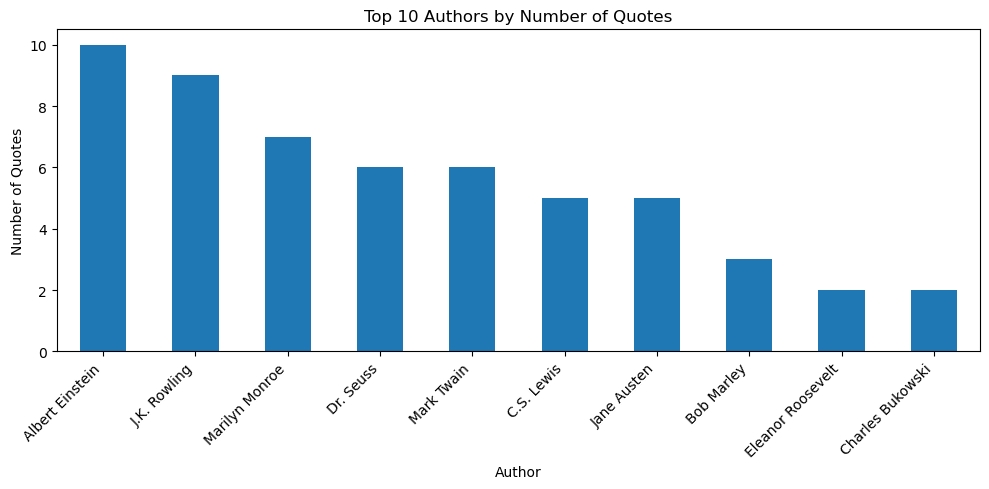

In [18]:
import matplotlib.pyplot as plt

top_authors = df["Author"].value_counts().head(10)

top_authors.plot(kind="bar",figsize=(10,5))

plt.title("Top 10 Authors by Number of Quotes")
plt.xlabel("Author")
plt.ylabel("Number of Quotes")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()

plt.savefig("top_10_authors.png", dpi=300, bbox_inches="tight")
plt.show()